# 09 — Final Evaluation, Business Analysis and Model Artifact
### Telco Customer Churn Prediction

All modelling decisions were fixed on training data in notebooks 00–08:
- preprocessing and features (00);
- algorithm and hyperparameters (01–06, 08);
- class-imbalance strategy (07, 08);
- threshold (08).

This notebook:
1. evaluates the selected pipeline **once** on the held-out test set;
2. analyses the business implications;
3. states the limitations;
4. saves the final model artifact.

**Three kinds of evidence are kept separate throughout:**

| Evidence | Data | Where |
|---|---|---|
| Training-stage (cross-validation) estimates | Nested OOF predictions on the 3,944 training customers | Notebooks 01–08 |
| Final internal holdout estimate | The 986-customer test set, from the same dataset | This notebook, Section 2 |
| External validation | An independent dataset from another source or period | **Not available** (Section 5) |

> **Disclosure — previous test-set exposure.** During earlier iterations of this project, the same test set was scored by two earlier versions of the pipeline before this restructuring. No model, feature, hyperparameter or threshold decision was based on those scores; every decision here comes from training data and rules fixed in advance. Still, a test set that has been looked at more than once is no longer a perfectly fresh estimate, and the results below should be read with that in mind.

## 1. Setup and Final Configuration

In [1]:
import sys
from pathlib import Path

# Make the project's shared src/ package importable, wherever Jupyter was started
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "data_preprocessing.py").exists())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))


import json
import platform
import pickle
import subprocess
from datetime import date

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.base import clone
from sklearn.metrics import classification_report, precision_recall_curve, roc_curve
from sklearn.model_selection import FixedThresholdClassifier

from src.data_preprocessing import (FEATURES, RANDOM_STATE, RAW_DATA_RELATIVE, TARGET, load_raw_data,
                                    split_features_target, split_train_test)
from src.evaluation import (H_MONTHS, OFFER_MONTHS, SUCCESS_RATE, bootstrap_metrics, business_outcome,
                            classification_metrics, load_results, segment_performance)
from src.visualization import plot_confusion, plot_reliability, save_figure, set_style

set_style()
pd.set_option("display.max_columns", None)
df = load_raw_data()
X_train, X_test, y_train, y_test = split_train_test(df)

selection = json.loads((PROJECT_ROOT / "reports" / "model_selection.json").read_text())
selected = load_results(selection["selected_slug"])
FINAL_MODEL_NAME, FINAL_THRESHOLD = selection["selected_model"], selection["threshold"]
final_pipeline = selected["final_pipeline"]   # tuned and fitted on the training set only (notebook 0x, Section 8)
assert np.array_equal(selected["y_index"], y_train.index.to_numpy())
print(f"Final model: {FINAL_MODEL_NAME} | hyperparameters: {selection['final_hyperparameters']} | threshold: {FINAL_THRESHOLD}")
print(final_pipeline)

Final model: Logistic Regression | hyperparameters: {'C': 1, 'l1_ratio': 0.0} | threshold: 0.27
Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('binary',
                                                  OneHotEncoder(categories=[['No',
                                                                             'Yes'],
                                                                            ['No',
                                                                             'Yes']],
                                                                drop='first',
                                                                sparse_output=False),
                                                  ['Dependents',
                                                   'PaperlessBilling']),
                                                 ('addons',
                                                  FunctionTransformer(feature_names_out='one-to-one',
            

**Configuration evaluated.**
- The Logistic Regression pipeline selected in notebook 08:
  - preprocessing as in notebook 00;
  - `C = 1`, L2 penalty;
  - fitted on the 3,944 training customers.
- Customers with predicted churn probability **≥ 0.27** are classified as churn risks.
- The threshold minimises expected cost on nested out-of-fold training predictions and agrees with the theoretical break-even of 0.278 (notebook 08, Section 5).

## 2. Final Test Evaluation (Internal Holdout)

The 986 test customers are scored once. **Bootstrap confidence intervals:** the test customers are resampled with replacement 1,000 times and each metric is recomputed. The 2.5th–97.5th percentile range describes sampling uncertainty of the test estimate only, not population change over time, and it is not used for any decision.

In [2]:
proba_test = final_pipeline.predict_proba(X_test)[:, 1]
pred_test = (proba_test >= FINAL_THRESHOLD).astype(int)
y_test_arr = y_test.to_numpy()

test_metrics = classification_metrics(y_test_arr, pred_test, proba_test)
boot = bootstrap_metrics(y_test_arr, pred_test, proba_test)
p_oof = selected["oof"]
training_estimate = classification_metrics(y_train.to_numpy(), (p_oof >= FINAL_THRESHOLD).astype(int), p_oof)
test_report = pd.DataFrame({"test (internal holdout)": test_metrics, "95% CI low": boot.quantile(0.025),
                            "95% CI high": boot.quantile(0.975), "training estimate (nested OOF)": training_estimate})
display(test_report.round(4))
print(classification_report(y_test_arr, pred_test, target_names=["No churn", "Churn"], digits=3))

,test (internal holdout),95% CI low,95% CI high,training estimate (nested OOF)
Accuracy,0.7465,0.7211,0.7738,0.7485
Precision,0.5157,0.4688,0.5631,0.5186
Recall,0.8099,0.7643,0.8587,0.8063
F1,0.6302,0.5886,0.6731,0.6312
ROC-AUC,0.8540,0.8295,0.8784,0.8437
PR-AUC,0.6846,0.6260,0.7414,0.6575
Brier score,0.1323,0.1209,0.1433,0.1362


              precision    recall  f1-score   support

    No churn      0.913     0.723     0.807       723
       Churn      0.516     0.810     0.630       263

    accuracy                          0.746       986
   macro avg      0.714     0.767     0.719       986
weighted avg      0.807     0.746     0.760       986



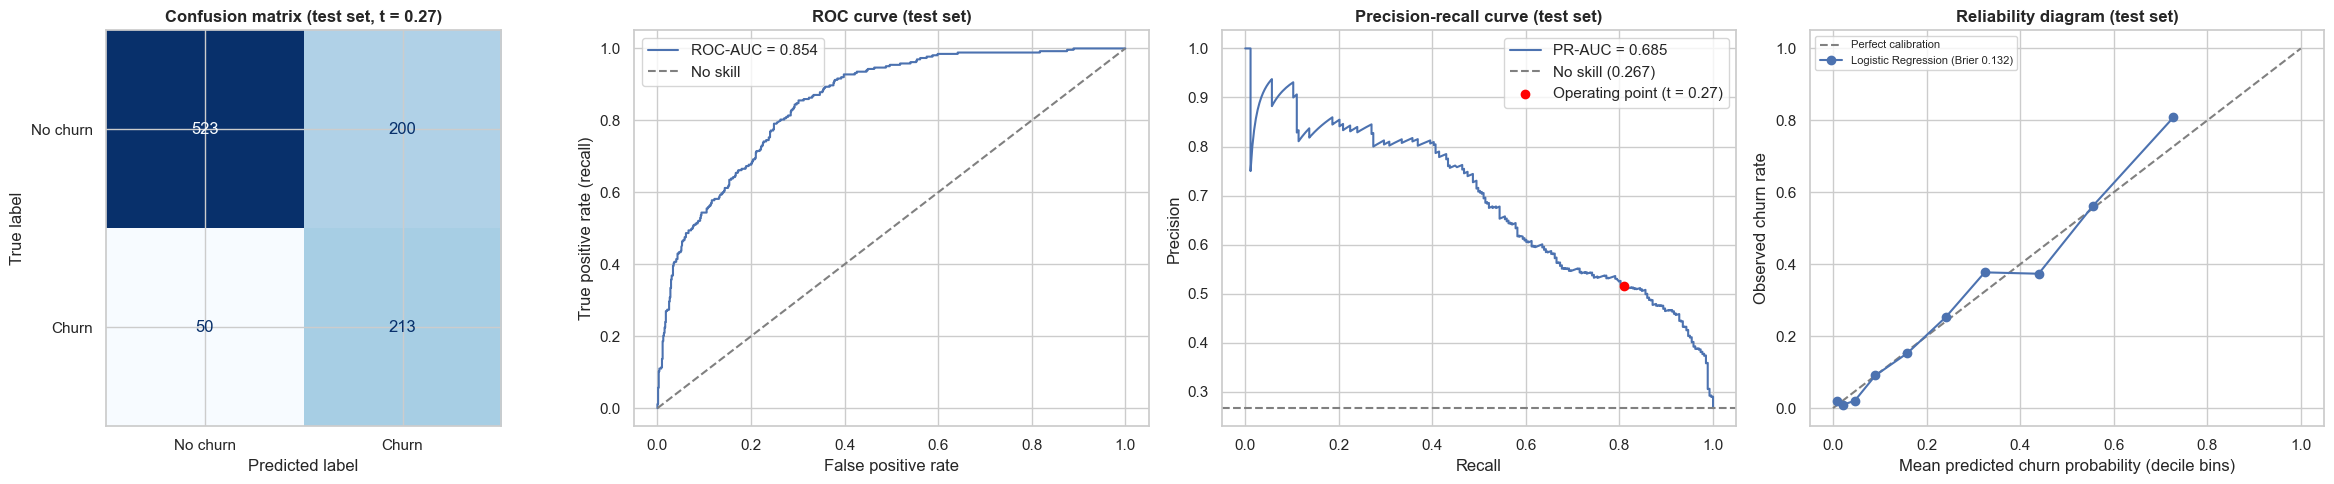

TP = 213, FP = 200, FN = 50, TN = 523 (total = 986)
Test performance by Contract (descriptive only)


,n,churners,churn rate,flagged (%),precision,recall,accuracy
Contract,,,,,,,
Month-to-month,541.0,233.0,0.431,75.231,0.521,0.910,0.601
One year,215.0,23.0,0.107,2.791,0.167,0.043,0.874
Two year,230.0,7.0,0.030,0.000,NaN,0.000,0.970


Test performance by tenure band (descriptive only)


,n,churners,churn rate,flagged (%),precision,recall,accuracy
tenure band,,,,,,,
0-12,284.0,143.0,0.504,77.817,0.602,0.930,0.655
13-24,152.0,50.0,0.329,51.974,0.519,0.820,0.691
25-48,227.0,40.0,0.176,33.480,0.329,0.625,0.709
49-72,323.0,30.0,0.093,11.455,0.378,0.467,0.879


In [3]:
fig, axes = plt.subplots(1, 4, figsize=(24, 5))
plot_confusion(axes[0], y_test_arr, pred_test, f"Confusion matrix (test set, t = {FINAL_THRESHOLD:.2f})")
fpr, tpr, _ = roc_curve(y_test_arr, proba_test)
axes[1].plot(fpr, tpr, label=f"ROC-AUC = {test_metrics['ROC-AUC']:.3f}")
axes[1].plot([0, 1], [0, 1], linestyle="--", color="gray", label="No skill")
axes[1].set_title("ROC curve (test set)")
axes[1].set_xlabel("False positive rate")
axes[1].set_ylabel("True positive rate (recall)")
axes[1].legend()
prec, rec, _ = precision_recall_curve(y_test_arr, proba_test)
axes[2].plot(rec, prec, label=f"PR-AUC = {test_metrics['PR-AUC']:.3f}")
axes[2].axhline(y_test_arr.mean(), linestyle="--", color="gray", label=f"No skill ({y_test_arr.mean():.3f})")
axes[2].scatter([test_metrics["Recall"]], [test_metrics["Precision"]], color="red", zorder=5,
                label=f"Operating point (t = {FINAL_THRESHOLD:.2f})")
axes[2].set_title("Precision-recall curve (test set)")
axes[2].set_xlabel("Recall")
axes[2].set_ylabel("Precision")
axes[2].legend()
plot_reliability(axes[3], y_test_arr, {FINAL_MODEL_NAME: proba_test}, "Reliability diagram (test set)")
plt.tight_layout()
save_figure(fig, "09_test_evaluation")
plt.show()

tn, fp, fn, tp = np.bincount(2 * y_test_arr + pred_test, minlength=4)
print(f"TP = {tp}, FP = {fp}, FN = {fn}, TN = {tn} (total = {tn + fp + fn + tp})")
test_seg = X_test.assign(actual=y_test_arr, pred=pred_test)
test_seg["tenure band"] = pd.cut(test_seg["tenure"], bins=[-1, 12, 24, 48, 72], labels=["0-12", "13-24", "25-48", "49-72"])
for segment in ["Contract", "tenure band"]:
    print(f"Test performance by {segment} (descriptive only)")
    display(segment_performance(test_seg, segment).round(3))

**Interpretation** (986 held-out customers, threshold 0.27)

| Metric | Test | 95% bootstrap CI | Training estimate (nested OOF) |
|---|---|---|---|
| Recall | **0.810** | 0.764–0.859 | 0.806 |
| Precision | **0.516** | 0.469–0.563 | 0.519 |
| F1 | **0.630** | 0.589–0.673 | 0.631 |
| Accuracy | 0.747 | 0.721–0.774 | 0.749 |
| ROC-AUC | **0.854** | 0.830–0.878 | 0.844 |
| PR-AUC | **0.685** | 0.626–0.741 | 0.658 |
| Brier score | 0.132 | 0.121–0.143 | 0.136 |

**Confusion matrix**
- Of 263 churners, the model flags **213** (TP) and misses **50** (FN).
- Of 723 non-churners, it flags **200** unnecessarily (FP) and leaves 523 alone (TN).
- 413 customers (42%) would be contacted, and **52% of them are real churners**, about twice the 27% base rate.

**Agreement with the training-stage estimates**
- Recall, precision, F1, accuracy and Brier score are within 0.004 of the nested estimates.
- The test ROC-AUC and PR-AUC are somewhat higher, but the training values lie inside the bootstrap intervals. This is ordinary sampling variation in 986 customers, not evidence that the model is better than estimated.
- Overlapping intervals do not prove two quantities are equal; they only show that the data cannot distinguish them.

**Calibration on unseen data:** the test reliability curve stays close to the diagonal (Brier 0.132), so the probabilities remain meaningful outside the training data.

**Segments** (descriptive only)
- Month-to-month customers: recall **0.91**. First-year customers: 0.93.
- One-year contracts: only 1 of 23 churners is flagged. Two-year contracts: 0 of 7.
- The model is reliable for the high-risk segments and blind to churn among committed customers.

## 3. Business Cost Analysis

Three strategies are compared on the **same 986 test customers** with the **same hypothetical assumptions** as notebook 08:
- 12-month horizon;
- 30% retention success rate;
- offer = one month of charges.

The strategies:
1. **Do nothing** — no customer is contacted.
2. **Contact everyone** — every customer receives the offer.
3. **Model-based intervention** — customers with predicted probability ≥ the operating threshold are contacted.

Terms used below:
- **Revenue at risk** — 12 months of charges of the customers who will churn.
- **Expected revenue retained** — revenue at risk among contacted churners × the assumed success rate.
- **Offer spend** — the campaign cost.
- **Total expected cost** — offer spend + expected revenue lost.

None of these is **profit**: serving costs and margins are unknown. None is a **realised saving**: the success rate is assumed, not measured.

,customers contacted,offer spend,revenue at risk (churners),expected revenue retained,expected revenue lost,total expected cost,churners reached,saving vs do nothing (%)
Do nothing,0.0,0.0,236716.8,0.0,236716.8,236716.8,0,0.0
Contact everyone,986.0,64934.8,236716.8,71015.0,165701.8,230636.6,263,2.6
"Model (Logistic Regression, t = 0.27)",413.0,31245.0,236716.8,58785.1,177931.7,209176.7,213,11.6


Expected revenue lost by the model strategy: 40,766.4 from missed churners (FN) + 137,165.3 from contacted churners whose offer fails
Share of contact-everyone offer spend going to customers who would have stayed: 69.6%


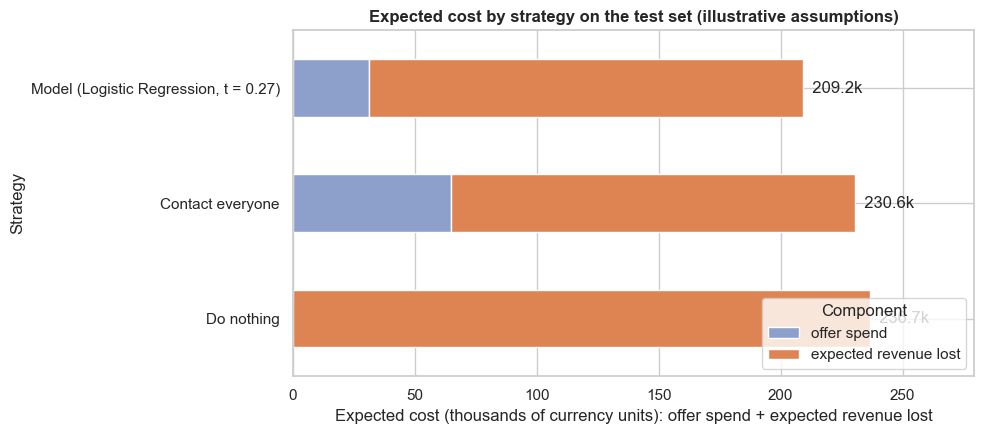

In [4]:
monthly_test = X_test["MonthlyCharges"].to_numpy()
model_label = f"Model ({FINAL_MODEL_NAME}, t = {FINAL_THRESHOLD:.2f})"
strategies = {"Do nothing": np.zeros(len(y_test_arr), dtype=int), "Contact everyone": np.ones(len(y_test_arr), dtype=int),
              model_label: pred_test}
cba = pd.DataFrame({name: business_outcome(y_test_arr, pred, monthly_test) for name, pred in strategies.items()}).T
cba["churners reached"] = [int(((pred == 1) & (y_test_arr == 1)).sum()) for pred in strategies.values()]
cba["saving vs do nothing (%)"] = 100 * (1 - cba["total expected cost"] / cba.loc["Do nothing", "total expected cost"])
display(cba.round(1))

contacted = pred_test == 1
lost_missed = (H_MONTHS * monthly_test[~contacted & (y_test_arr == 1)]).sum()
lost_failed_offers = ((1 - SUCCESS_RATE) * H_MONTHS * monthly_test[contacted & (y_test_arr == 1)]).sum()
assert np.isclose(OFFER_MONTHS * monthly_test[contacted].sum() + lost_missed + lost_failed_offers,
                  cba.loc[model_label, "total expected cost"]), "Cost arithmetic mismatch"
print(f"Expected revenue lost by the model strategy: {lost_missed:,.1f} from missed churners (FN) + "
      f"{lost_failed_offers:,.1f} from contacted churners whose offer fails")
print("Share of contact-everyone offer spend going to customers who would have stayed: "
      f"{monthly_test[y_test_arr == 0].sum() / monthly_test.sum():.1%}")

fig, ax = plt.subplots(figsize=(10, 4.5))
(cba[["offer spend", "expected revenue lost"]] / 1e3).plot.barh(stacked=True, ax=ax, color=["#8DA0CB", "#DD8452"])
for i, total in enumerate(cba["total expected cost"] / 1e3):
    ax.text(total, i, f"  {total:,.1f}k", va="center")
ax.set_title("Expected cost by strategy on the test set (illustrative assumptions)")
ax.set_xlabel("Expected cost (thousands of currency units): offer spend + expected revenue lost")
ax.set_ylabel("Strategy")
ax.set_xlim(0, cba["total expected cost"].max() / 1e3 * 1.18)
ax.legend(title="Component", loc="lower right")
plt.tight_layout()
save_figure(fig, "09_cost_comparison")
plt.show()

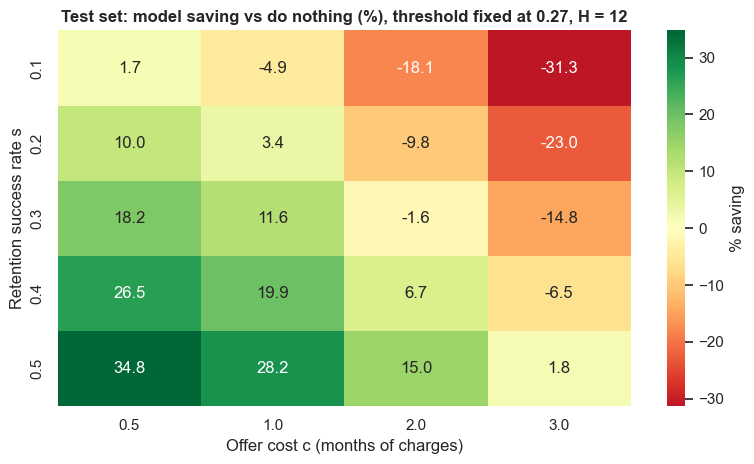

Cheapest strategy per scenario (H = 12):


offer cost c,0.5,1.0,2.0,3.0
success rate s,,,,
0.1,Model,Do nothing,Do nothing,Do nothing
0.2,Model,Model,Do nothing,Do nothing
0.3,Model,Model,Do nothing,Do nothing
0.4,Model,Model,Model,Do nothing
0.5,Contact everyone,Model,Model,Model


Strategy counts: {'Model': 11, 'Do nothing': 8, 'Contact everyone': 1}


,cheapest strategy,model saving vs do nothing (%)
horizon H (months),,
6,Do nothing,-1.57
12,Model,11.63
24,Model,18.23


In [5]:
success_grid, offer_grid = [0.10, 0.20, 0.30, 0.40, 0.50], [0.5, 1.0, 2.0, 3.0]


def compare(**kw):
    costs = {name: business_outcome(y_test_arr, pred, monthly_test, **kw)["total expected cost"]
             for name, pred in strategies.items()}
    best = min(costs, key=costs.get)
    return ("Model" if best == model_label else best), 100 * (1 - costs[model_label] / costs["Do nothing"])


best_sc = pd.DataFrame(index=success_grid, columns=offer_grid, dtype=object)
saving_sc = pd.DataFrame(index=success_grid, columns=offer_grid, dtype=float)
for s_val in success_grid:
    for c_val in offer_grid:
        best_sc.loc[s_val, c_val], saving_sc.loc[s_val, c_val] = compare(success=s_val, offer_months=c_val)
best_sc.index.name, best_sc.columns.name = "success rate s", "offer cost c"
fig, ax = plt.subplots(figsize=(8, 4.8))
sns.heatmap(saving_sc, annot=True, fmt=".1f", cmap="RdYlGn", center=0, ax=ax, cbar_kws={"label": "% saving"})
ax.set_title(f"Test set: model saving vs do nothing (%), threshold fixed at {FINAL_THRESHOLD:.2f}, H = 12")
ax.set_xlabel("Offer cost c (months of charges)")
ax.set_ylabel("Retention success rate s")
plt.tight_layout()
save_figure(fig, "09_cost_sensitivity")
plt.show()
print("Cheapest strategy per scenario (H = 12):")
display(best_sc)
print("Strategy counts:", best_sc.stack().value_counts().to_dict())
display(pd.DataFrame([{"horizon H (months)": h, "cheapest strategy": compare(horizon=h)[0],
                       "model saving vs do nothing (%)": compare(horizon=h)[1]} for h in [6, 12, 24]])
        .set_index("horizon H (months)").round(2))

**Interpretation** (test set; revenue at risk under hypothetical assumptions — not profit, not realised savings)

| Strategy | Contacted | Churners reached | Offer spend | Expected revenue lost | Total expected cost | vs do nothing |
|---|---|---|---|---|---|---|
| Do nothing | 0 | 0 / 263 | 0 | 236,717 | 236,717 | — |
| Contact everyone | 986 | 263 / 263 | 64,935 | 165,702 | 230,637 | −2.6% |
| **Model (t = 0.27)** | **413** | **213 / 263** | **31,245** | **177,932** | **209,177** | **−11.6%** |

- **Contacting everyone is inefficient.** It retains the most revenue (71,015 expected vs 58,785), but **70% of its offer spend goes to customers who would have stayed**, so its total cost is only 2.6% below doing nothing.
- **The model strategy has the lowest expected cost:** 11.6% below doing nothing and 9.3% below contacting everyone. It reaches 81% of churners while contacting 42% of customers. This matches the training estimate (11.9%).
- **Where the remaining cost comes from.** Of the 177,932 expected revenue lost:
  - 137,165 comes from **contacted churners whose offer fails** (70% under s = 0.3);
  - only 40,766 comes from the 50 missed churners.
  - **The model's value is capped by the effectiveness of the retention offer more than by its own errors.**

**Sensitivity (threshold fixed at 0.27)**
- **The model is the cheapest strategy in 11 of 20 (s, c) scenarios.**
- **"Do nothing" wins in 8**, all with expensive or ineffective offers: c ≥ 2 with s ≤ 0.3, c = 3 with s = 0.4, or c ≥ 1 with s = 0.1.
- **"Contact everyone" wins in 1** (s = 0.5, c = 0.5).
- With a **6-month horizon**, the model at t = 0.27 is 1.6% worse than doing nothing. The H = 6 optimum is 0.54 (notebook 08), so the threshold must be re-derived when assumptions change.

**What this shows and does not show**
- It shows that, *if* the offer retains 30% of contacted churners at a cost of one month's charges, model-based targeting is cheaper than both simple alternatives.
- It does not show real savings: the success rate is assumed, revenue is not profit, and side effects of contacting customers are ignored.
- Only a controlled experiment (a random contacted group vs a control group) can measure the true effect.

## 4. External Validation Status

External validation means evaluating the frozen model, at the fixed threshold, on an **independent** dataset from another source or period, with compatible features and target. The project folder is checked for such a dataset.

In [6]:
external_dir = PROJECT_ROOT / "data" / "external"
if not external_dir.exists():
    print(f"{external_dir.relative_to(PROJECT_ROOT).as_posix()}/ does not exist in this project.")
candidates = []
for path in sorted(external_dir.glob("*")) if external_dir.exists() else []:
    content = path.read_text(errors="replace")
    print(f"{path.relative_to(PROJECT_ROOT)}: {len(content.splitlines())} line(s); first line: {content.splitlines()[0] if content else ''!r}")
    if path.suffix == ".csv" and set(FEATURES + [TARGET]) <= set(pd.read_csv(path, nrows=0).columns):
        candidates.append(path.name)
print("Compatible external datasets found:", candidates or "none")

data/external/ does not exist in this project.
Compatible external datasets found: none


**Result: external validation was not performed.**
- No independent dataset with compatible features and target exists in the project. (The course template's `data/external/` folder only ever held a one-line `Sample Data` placeholder and has been removed.)
- The 986-customer test set comes from the same dataset, period and population as the training data. It is an **internal holdout**, not external validation.
- How the model performs on customers from another time period, region or company is therefore **unknown**.

## 5. Limitations

**Validation**
- **Internal validation only:** one stratified split of a single dataset, with no external validation (Section 4). With 263 test churners, the metric intervals are several points wide.
- **Previous test-set exposure:** the test set was scored by two earlier pipeline versions during the project. No decision used those scores, but the holdout is no longer perfectly fresh.
- **Residual optimism:** encoding and feature-engineering choices (notebook 00) used the same CV folds that later served as outer folds, and the model was selected among six candidates on the same nested results. The close agreement between nested and test results suggests the effect is negligible.

**Data**
- **Only ten attributes:** no usage, complaints, support tickets, payment history or contract end dates. The ceiling of about 0.665 PR-AUC, shared by six different algorithms, indicates that missing information limits performance more than model choice does.
- **Undocumented origin, single snapshot:** patterns may not hold for other markets or later periods (**concept drift**).
- **No customer identifier:** the 77 duplicates are assumed to be distinct customers.
- **Survivorship:** long-tenure customers are partly "those who have not churned yet", which inflates the apparent protective effect of tenure.

**Model**
- **Blind to churn among committed customers:** one- and two-year contracts, and long tenure.
- **Linear and additive on the log-odds scale.** Boosting models that could represent interactions did not improve on it, but that could change with richer data.
- **Collinearity** between `MonthlyCharges` and service type makes individual coefficients less reliable than their joint effect.

**Business**
- All financial figures are **hypothetical** and measure revenue at risk, not profit.
- They ignore serving costs, contact capacity and customer reactions to offers.

## 6. Recommendations

**Business**
1. **Use the model as a monthly risk ranking.** Contact customers with predicted probability ≥ 0.27, in order of risk. Because the probabilities are calibrated, the scores can be quoted as approximate risk levels.
2. **Prioritise month-to-month, fiber-optic and first-year customers**, where churn concentrates and the model is most reliable (recall ≥ 0.91 on the test set). Actions *to test* include contract-upgrade incentives and early-life onboarding support.
3. **Run a controlled pilot before full rollout.** Randomly split flagged customers into contacted and control groups to measure the real retention success rate and offer cost. Then re-derive the threshold with $t \approx c/(sH)$ or the sensitivity analysis in notebook 08.
4. **Don't treat "not flagged" as "safe"** for customers on one- or two-year contracts. Monitor contract end dates and complaints separately.
5. **Investigate *why* fiber customers churn** (price, reliability, competition). The model shows the association, not the cause.

**Model and data**
1. **Collect richer features:** usage trends, support tickets, complaints, payment delays, contract end dates and past offers. Six algorithms reaching the same ceiling shows that more of the same information will not help.
2. **Seek external validation:** score a later period or a different customer base with the frozen model and threshold.
3. **Keep XGBoost and LightGBM as challengers.** Re-evaluate them when new features become available.
4. **Monitor after deployment:**
   - realised precision and recall of flagged customers;
   - calibration;
   - input drift.
   - Retrain when performance degrades or prices or products change.

## 7. Conclusion

**Can churn be predicted, and with which model?**
- Yes, moderately well.
- Six algorithms were compared with nested cross-validation. Five reached the same ranking quality (PR-AUC 0.657–0.666, ROC-AUC about 0.845).
- **Logistic Regression** with a log-transformed tenure feature was selected: it is the most interpretable, the most stable, well calibrated, and tied for the best score.
- Neither class weighting nor resampling (including SMOTENC) improved it.

**How well does it work on unseen customers?**
- On the 986-customer internal holdout, at threshold 0.27, the model catches **81% of churners (213 of 263)** with **52% precision**, ROC-AUC 0.854 and PR-AUC 0.685.
- These results agree with the training-stage estimates.

**What is it worth?**
- Under illustrative assumptions (12-month horizon, 30% offer success, offer = one month of charges), targeting the flagged 42% of customers has the lowest expected cost. That is 11.6% less revenue at risk than doing nothing and 9.3% less than contacting everyone.
- The value depends on offer economics that only a controlled pilot can measure.

**Practical value:** the project provides the Customer Success team with a transparent, calibrated risk score, a decision rule tied to campaign economics, and a clear statement of where the score can and cannot be trusted.

## 8. Final Model Artifact

All decisions are final. Following standard practice, the selected configuration is **refitted on all 4,930 labelled customers** (training + test) so that the deployed model uses every available observation:
- the hyperparameters and the threshold stay exactly as selected on the training data;
- no tuning is repeated.

The performance figures above remain the estimates for this model. The refitted artifact itself has no remaining unseen data, so its own performance on the full data must **not** be reported as a test result.

The artifact is a scikit-learn `FixedThresholdClassifier` wrapping the complete pipeline. It accepts the 10 original columns as a DataFrame:
- `predict_proba` returns churn probabilities;
- `predict` applies the 0.27 threshold.

The pipeline references the encoding function in `src/data_preprocessing.py`, so the project's `src/` package must be importable when loading.

> **Security:** pickle files can execute code when loaded. Only load `churn_pipeline.pkl` from this trusted project.

In [7]:
X_all, y_all = split_features_target(df)
deployed_model = FixedThresholdClassifier(clone(final_pipeline), threshold=FINAL_THRESHOLD, response_method="predict_proba")
deployed_model.fit(X_all, y_all)

models_dir = PROJECT_ROOT / "models"
models_dir.mkdir(exist_ok=True)
with open(models_dir / "churn_pipeline.pkl", "wb") as fh:
    pickle.dump(deployed_model, fh)

import imblearn, lightgbm, matplotlib, scipy, xgboost
metadata = {
    "model_name": FINAL_MODEL_NAME,
    "model_type": type(deployed_model.estimator_.named_steps["model"]).__name__,
    "artifact": "models/churn_pipeline.pkl (sklearn FixedThresholdClassifier wrapping Pipeline[preprocess, model])",
    "training_date": date.today().isoformat(),
    "trained_on": f"all {len(X_all)} labelled customers (training + test) after all decisions were fixed on the training set",
    "feature_names": list(deployed_model.feature_names_in_),
    "encoded_feature_names": list(deployed_model.estimator_.named_steps["preprocess"].get_feature_names_out()),
    "target": {"name": TARGET, "positive_class": "Yes (1)"},
    "random_state": RANDOM_STATE,
    "threshold": FINAL_THRESHOLD,
    "threshold_rule": selection["threshold_rule"],
    "hyperparameters": selection["final_hyperparameters"],
    "class_imbalance_strategy": selection["class_imbalance_strategy"],
    "preprocessing_steps": [f"{name}: {type(tr).__name__} on {cols}" for name, tr, cols in
                            deployed_model.estimator_.named_steps["preprocess"].transformers_ if name != "remainder"],
    "cross_validation_metrics_training": selection["nested_cv_metrics"],
    "internal_holdout_metrics_test": {k: round(float(v), 4) for k, v in test_metrics.items()},
    "external_validation": "not performed - no independent dataset available",
    "known_limitations": [
        "Internal validation only (one stratified split of one dataset); no external validation.",
        "Preprocessing and feature-set choices (notebook 00) were made with ordinary CV on the same training folds later used as outer folds; a fully nested re-check for Logistic Regression changed mean PR-AUC only marginally (notebook 08, Section 6).",
        "The test set was scored by earlier pipeline versions before this final evaluation.",
        "Weak detection of churners on one- and two-year contracts.",
        "Business cost figures rely on hypothetical assumptions and measure revenue at risk, not profit.",
        "Requires the project's src/ package to be importable when unpickling.",
    ],
    "package_versions": {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
                         "scikit-learn": sklearn.__version__, "scipy": scipy.__version__, "joblib": joblib.__version__,
                         "matplotlib": matplotlib.__version__, "seaborn": sns.__version__,
                         "imbalanced-learn": imblearn.__version__, "xgboost": xgboost.__version__,
                         "lightgbm": lightgbm.__version__},
    "security_note": "Pickle files can execute arbitrary code when loaded; load only from this trusted project.",
}
(models_dir / "model_metadata.json").write_text(json.dumps(metadata, indent=2))
print(json.dumps({k: metadata[k] for k in ["model_name", "model_type", "trained_on", "threshold", "hyperparameters"]}, indent=2))

{
  "model_name": "Logistic Regression",
  "model_type": "LogisticRegression",
  "trained_on": "all 4930 labelled customers (training + test) after all decisions were fixed on the training set",
  "threshold": 0.27,
  "hyperparameters": {
    "C": 1,
    "l1_ratio": 0.0
  }
}


### Verification in a fresh Python process

The artifact is loaded in a **separate** Python process, so nothing from this notebook's memory is reused. Five raw customers are scored, and the script checks:
- the feature names and their order;
- that probabilities lie in [0, 1];
- that `predict` equals `probability ≥ threshold`.

In [8]:
verification_script = f"""
import pickle, sys, json
import pandas as pd
sys.path.insert(0, r"{PROJECT_ROOT}")
with open(r"{models_dir / 'churn_pipeline.pkl'}", "rb") as fh:
    model = pickle.load(fh)
meta = json.load(open(r"{models_dir / 'model_metadata.json'}"))
sample = pd.read_csv(r"{PROJECT_ROOT / RAW_DATA_RELATIVE}").drop(columns="{TARGET}").head(5)
assert list(model.feature_names_in_) == meta["feature_names"] == list(sample.columns), "feature names/order mismatch"
proba = model.predict_proba(sample)[:, 1]
pred = model.predict(sample)
assert ((proba >= 0) & (proba <= 1)).all()
assert (pred == (proba >= meta["threshold"]).astype(int)).all(), "threshold not applied correctly"
print("type:", type(model).__name__, "| threshold:", model.threshold)
print(pd.DataFrame({{"churn probability": proba.round(4), "prediction (1 = churn)": pred}}).to_string())
print("ALL CHECKS PASSED")
"""
completed = subprocess.run([sys.executable, "-c", verification_script], capture_output=True, text=True)
print(completed.stdout)
if completed.returncode != 0:
    raise RuntimeError(completed.stderr)

type: FixedThresholdClassifier | threshold: 0.27
   churn probability  prediction (1 = churn)
0             0.3887                       1
1             0.5472                       1
2             0.0114                       0
3             0.0118                       0
4             0.2850                       1
ALL CHECKS PASSED

